# Introduction - Exploratory Analysis

In this notebook, we will conduct an analysis of the data previously prepared in the path: `data/interim/hockey_teams.json`. This file, being partially processed, is easily accessible for import and ready for more detailed analytical examination.

This part of the workshop will focus on utilizing `pandas` and `matplotlib`, which were discussed during the course. The main objective is to familiarize ourselves with the dataset we are working on. Through a series of exercises:  
- we will get to know the structure of the data,  
- we will conduct elementary data exploration (EDA).

## Column Description

Below is a brief description of each column in our dataset:

- **Team Name**: The name of the team participating in the match.
- **Year**: The year in which the season takes place.
- **Wins**: The number of matches won by the team in the given season.
- **Losses**: The number of matches lost by the team in the given season.
- **OT Losses**: The number of matches lost by the team in overtime in the given season.
- **Win %**: The percentage of matches won by the team in the given season.
- **Goals For (GF)**: The number of goals scored by the team in the given season.
- **Goals Against (GA)**: The number of goals conceded by the team in the given season.
- **+ / -**: The difference between the number of goals scored and conceded by the team in the given season.

> Note: At this stage, certain significant simplifications were intentionally made in the analysis and they will not be explicitly mentioned, aiming for a discussion at the end of the workshop.

# Preparation

## Import libraries
Here, load the libraries that will be needed in the following steps

In [97]:
import pandas as pd
import matplotlib.pyplot as plt

# Loading the Dataset

We recommend loading the raw data into a variable with the suffix `_raw`. This will avoid the need to reload the data from the beginning in case of an error, which can be a time-consuming process.  
  
> **Tip:** A `json` file can be easily loaded using `pandas` with the `read_json` function - [click](https://pandas.pydata.org/docs/reference/api/pandas.read_json.html)  

Load data from the `hockey_teams` file here

In [5]:

df_raw = pd.read_json("../data/interim/hockey_teams.json")

df = df_raw



Check here if the data loaded correctly

In [24]:
df.head()
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Team                582 non-null    object 
 1   Season              582 non-null    int64  
 2   victories           582 non-null    int64  
 3   defeats             582 non-null    int64  
 4   overtime_defeats    582 non-null    int32  
 5   victory_percentage  582 non-null    float64
 6   scored_goals        582 non-null    int64  
 7   received_goals      582 non-null    int64  
 8   goal_difference     582 non-null    int64  
dtypes: float64(1), int32(1), int64(6), object(1)
memory usage: 38.8+ KB


# Preliminary Data Transformation

## Standardizing Column Names

Currently, our dataset contains original column names which, from a technical standpoint, should not contain spaces or other special characters.

In this section, we will standardize and simplify the naming conventions to facilitate data processing in subsequent stages. We will apply the following column name mapping:

- **Team Name** -> `team`
- **Year** -> `season`
- **Wins** -> `victories`
- **Losses** -> `defeats`
- **OT Losses** -> `overtime_defeats`
- **Win %** -> `victory_percentage`
- **Goals For (GF)** -> `scored_goals`
- **Goals Against (GA)** -> `received_goals`
- **\+ / -** -> `goal_difference`

> At this point, we recommend creating a new DataFrame without the `_raw` postfix. For example, if the data was loaded into the variable `df_raw`, we now want to work with the variable `df`, where we will modify the column names.

In [6]:
df.columns = ["Team", "Season", "victories", "defeats", "overtime_defeats", "victory_percentage", "scored_goals", "received_goals", "goal_difference"]
df

,Team,Season,victories,defeats,overtime_defeats,victory_percentage,scored_goals,received_goals,goal_difference
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25
...,...,...,...,...,...,...,...,...,...
577,Tampa Bay Lightning,1998,19,54,NaN,0.232,179,292,-113
578,Toronto Maple Leafs,1998,45,30,NaN,0.549,268,231,37
579,Vancouver Canucks,1998,23,47,NaN,0.280,192,258,-66
580,Washington Capitals,1998,31,45,NaN,0.378,200,218,-18


## Removing Empty Values

As can be observed, the `overtime_defeats` column contains many empty values, and the expected data type is `int`. Before proceeding with further analysis, this column needs to be properly prepared.

To achieve this, we will perform the following steps:
- Check which symbol is used as an indicator of an empty field.
- Fill the empty fields with a value of 0.
- Then convert the data type of this column to `int`.

By following these steps, the `overtime_defeats` column will be ready for further analysis.

### Finding the Indicator of an Empty Field

In [7]:
df["overtime_defeats"].unique()


array([nan,  4.,  6.,  5.,  0.,  2.,  1.,  8.,  7.,  3.,  9., 12., 16.,
       11., 13., 14., 15., 10., 18.])

### Overwriting Empty Values with 0

In [8]:
df["overtime_defeats"].fillna(0, inplace=True)

C:\Users\TomasUher\AppData\Local\Temp\ipykernel_28888\1089517724.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["overtime_defeats"].fillna(0, inplace=True)


### Column Type Conversion

In [9]:
df["overtime_defeats"] = df["overtime_defeats"].fillna(0).astype(int)
print(df["overtime_defeats"].dtype)  # mělo by vypsat int




int32


# Dataset Analysis

In this section, we will focus on answering fundamental questions about our dataset in the context of hockey games. The goal is to become familiar with the dataset and develop an intuition about it.  
  
Here is a list of exercises we will perform to find answers to key questions:  
  
- How many teams have participated in league games over the years?  
- What is the total number of available seasons?  
- What is the time span of the data?  
- Are there any suspicious or outlier values in the numerical columns?  
  
These exercises will help us better understand the structure and nature of our data.  

### Number of teams that participated in league matches

Here, indicate the total number of teams available in our dataset

In [12]:
number_team = df["Team"].count()
print(number_team)
# 582 teams 

582


### Total number of seasons

Here, indicate the total number of seasons.

In [14]:
number_season = df["Season"].nunique()
print(number_season)
#21 sezon

21


### Time Span of Data

Here, we will examine the availability of data for individual seasons. The analysis will be conducted in two stages:  
- First, we will determine the time range of the data by identifying the start year (`start_year`) and the end year (`end_year`). This will allow us to establish for which seasons we have information.  
- Next, we will look for any gaps in the time data to ensure that we have a complete set of information for each season.   

At this point, we will determine the start year and end year of the data:

In [17]:
start_year = df["Season"].min()
end_year = df["Season"].max()

print(f"Data pokrývají období od roku {start_year} do roku {end_year}.")

Data pokrývají období od roku 1990 do roku 2011.


Here, we will check if data is present for each year within the determined range:

In [21]:
season_df = sorted(df["Season"].unique())
sezony = list(range(start_year, end_year + 1))
print(sezony)

[1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011]


### Analysis of Numerical Columns

Here we will examine the basic descriptive statistics for numerical columns.

To this end, describe and analyze the results for the following columns:

- victories
- defeats
- overtime_defeats
- victory_percentage
- scored_goals
- received_goals
- goal_difference

We are interested in the following statistics:
- mean,
- count,
- standard deviation,
- percentiles = `[0, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 1]`

In [23]:
percentiles = [0, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 1]
columns = [
    "victories",
    "defeats",
    "overtime_defeats",
    "victory_percentage",
    "scored_goals",
    "received_goals",
    "goal_difference"
]

# statistika
desc_stats = df[columns].describe(percentiles=percentiles).T  # .T otočí tabulku pro lepší čitelnost
desc_stats = desc_stats.round(2)  # zaokrouhlení
print(desc_stats)

# napriklad se z vysledku dovime ze ze 50 procent melo maximalni pocet vyher 38 a mene. 

                    count    mean    std     min      0%      5%     10%  \
victories           582.0   36.94   8.93    9.00    9.00   21.05   24.10   
defeats             582.0   32.35   8.41   11.00   11.00   20.00   23.00   
overtime_defeats    582.0    4.59   4.61    0.00    0.00    0.00    0.00   
victory_percentage  582.0    0.46   0.10    0.12    0.12    0.28    0.32   
scored_goals        582.0  234.06  40.55  115.00  115.00  175.05  190.10   
received_goals      582.0  234.06  42.51  115.00  115.00  168.05  187.00   
goal_difference     582.0    0.00  45.28 -196.00 -196.00  -72.00  -57.00   

                       25%     50%     75%     90%     95%    100%     max  
victories            31.00   38.00   43.00   48.00   50.00   62.00   62.00  
defeats              27.00   31.00   37.00   43.00   47.00   71.00   71.00  
overtime_defeats      0.00    4.00    8.00   11.00   13.00   18.00   18.00  
victory_percentage    0.39    0.46    0.53    0.58    0.62    0.76    0.76  
scored

# `team`

In this section, we will conduct a series of analyses on individual teams participating in the leagues. This will allow us to identify the teams that have performed best in the competitions over the years.


## Analysis of Team Participation in League Seasons
Let's perform the following exercises:

- Check how many teams have participated in all seasons of the selected league.
- Display the list of these teams.

In [52]:
tym_vsechny = []

# Seznam všech sezón
sezony = sorted(df["Season"].unique())

# Iterace přes všechny týmy
for tym in df["Team"].unique():
    # Sezóna, ve které tým skutečně hrál
    tym_sezony = df[df["Team"] == tym]["Season"].tolist()
    
    # Kontrola, zda tým hrál ve všech sezónách
    if all(sezona in tym_sezony for sezona in sezony):
        tym_vsechny.append(tym)
        

# Výsledek
print(f"Týmy, které hrály ve všech sezónách: {tym_vsechny}")

print(f"Ve vsech sezonach hralo: {len(tym_vsechny)} tymu")



Týmy, které hrály ve všech sezónách: ['Boston Bruins', 'Buffalo Sabres', 'Calgary Flames', 'Chicago Blackhawks', 'Detroit Red Wings', 'Edmonton Oilers', 'Los Angeles Kings', 'Montreal Canadiens', 'New Jersey Devils', 'New York Islanders', 'New York Rangers', 'Philadelphia Flyers', 'Pittsburgh Penguins', 'St. Louis Blues', 'Toronto Maple Leafs', 'Vancouver Canucks', 'Washington Capitals']
Ve vsech sezonach hralo: 17 tymu


List of teams that participated in all seasons of hockey competitions:

In [53]:
print(f"Týmy, které hrály ve všech sezónách: {tym_vsechny}")

Týmy, které hrály ve všech sezónách: ['Boston Bruins', 'Buffalo Sabres', 'Calgary Flames', 'Chicago Blackhawks', 'Detroit Red Wings', 'Edmonton Oilers', 'Los Angeles Kings', 'Montreal Canadiens', 'New Jersey Devils', 'New York Islanders', 'New York Rangers', 'Philadelphia Flyers', 'Pittsburgh Penguins', 'St. Louis Blues', 'Toronto Maple Leafs', 'Vancouver Canucks', 'Washington Capitals']


The number of teams that have played in all seasons:

In [54]:
print(f"Ve vsech sezonach hralo: {len(tym_vsechny)} tymu")

Ve vsech sezonach hralo: 17 tymu


## Best Performing Teams in League History

Let's list the five best teams with the highest average `victory_percentage` over all years, presenting the data broken down by individual teams and seasons.

In [ ]:
df_top5 = df[df["Team"].isin(top5_tymy)]

# průměr z victory_percentage
df_top5_unique = df_top5.groupby("Team", as_index=False)["victory_percentage"].mean()

# seřadíme podle průměru
df_top5_unique_sorted = df_top5_unique.sort_values("victory_percentage", ascending=False)





## Top Teams in History

Let's determine the top 5 teams that have won the most league titles in entire history. Let's consider whether, based on the available data, we can identify a single team that unquestionably deserves the title of the best in history.

For simplicity, let's assume that the league winner is the team with the most victories in a given season.

> Hint: The information contained in the article `Pandas > Summary of the 4th Meeting > Analytical Functions` may be useful.

In [75]:
df_top5_unique = [1 if x == 0 else x for x in top5_tymy]
for i, tym in enumerate(df_top5_unique, start=1):
    print(f"{i}. {tym}")

1. Detroit Red Wings
2. New Jersey Devils
3. Anaheim Ducks
4. Dallas Stars
5. Colorado Avalanche


Additionally, we will determine how many teams have **never won any season**.  
  
> **Note:** This task may seem more complex than it appears at first glance. Remember, during classes you can rely on the instructor's help, and outside of them - on the support of a mentor.

In [82]:
#  žádna vyhra
df_bez_vyher = df[df["victories"] == 0]

#  více proher než vyher
vetsipocetproher = df[df["defeats"] > df["victories"]][["Team", "Season", "victories", "defeats"]]

#  jednu sezonu bez výhry
tymy_bez_vyher = df_bez_vyher["Team"]

print("Týmy, které v některé sezóně nezískaly žádnou výhru:")
print(tymy_bez_vyher)
print(vetsipocetproher) 


Týmy, které v některé sezóně nezískaly žádnou výhru:
Series([], Name: Team, dtype: object)
                      Team  Season  victories  defeats
4        Detroit Red Wings    1990         34       38
6         Hartford Whalers    1990         31       38
8    Minnesota North Stars    1990         27       39
10       New Jersey Devils    1990         32       33
11      New York Islanders    1990         25       45
..                     ...     ...        ...      ...
570       New York Rangers    1998         33       38
575        San Jose Sharks    1998         31       33
577    Tampa Bay Lightning    1998         19       54
579      Vancouver Canucks    1998         23       47
580    Washington Capitals    1998         31       45

[211 rows x 4 columns]


# `overtime_defeats`

The `overtime_defeats` variable informs us how many times a team lost in overtime throughout the year.  
  
In this section, we will perform the following exercises:  
- Identify the team that most frequently lost in overtime.  
- Rank the teams based on the number of overtime losses.  
- Calculate what percentage of teams lost at least once in overtime.  
- Determine the season with the highest number of games decided in overtime.  
  
> Let's make sure that the `overtime_defeats` column is of numeric type!  

## The team losing most frequently in overtime

> Note: To solve this task, this article might be useful: `Pandas > Conference Summary > Analytical Functions`

In [85]:
# Ujistíme se, že sloupec je číselný
df["overtime_defeats"] = pd.to_numeric(df["overtime_defeats"], errors="coerce")

# Tým, který nejčastěji prohrál v prodloužení
nejvic_ot = df[df["overtime_defeats"] == df["overtime_defeats"].max()]["Team"].iloc[0]
print("Tým s nejvíc prohrami v prodloužení:", nejvic_ot)

# Pořadí týmů podle počtu proher v prodloužení (od nejvíc po nejmíň)
print("Pořadí týmů podle počtu proher v prodloužení:")
print(df.groupby("Team")["overtime_defeats"].sum().sort_values(ascending=False))



# Sezóna s nejvyšším počtem zápasů rozhodnutých v prodloužení
nejvic_sezona = df.groupby("Season")["overtime_defeats"].sum().idxmax()
print("Sezóna s nejvíc zápasy rozhodnutými v prodloužení:", nejvic_sezona)

Tým s nejvíc prohrami v prodloužení: Tampa Bay Lightning
Pořadí týmů podle počtu proher v prodloužení:
Team
Florida Panthers           124
Boston Bruins              106
St. Louis Blues            101
Tampa Bay Lightning         96
Montreal Canadiens          96
Toronto Maple Leafs         96
San Jose Sharks             94
Edmonton Oilers             94
Calgary Flames              94
Los Angeles Kings           93
Chicago Blackhawks          92
Washington Capitals         91
Philadelphia Flyers         91
New York Rangers            87
Columbus Blue Jackets       86
Pittsburgh Penguins         86
Carolina Hurricanes         86
New York Islanders          85
Detroit Red Wings           84
Ottawa Senators             83
Buffalo Sabres              83
Vancouver Canucks           82
Phoenix Coyotes             81
Minnesota Wild              80
Dallas Stars                80
Nashville Predators         79
Atlanta Thrashers           78
Colorado Avalanche          72
New Jersey Devils       

## Percentage of teams losing in overtime

The result of this task should be rounded to two decimal places

In [84]:
# Kolik procent týmů prohrálo alespoň jednou v prodloužení
pct = (df[df["overtime_defeats"] > 0]["Team"].nunique() / df["Team"].nunique()) * 100
print(f"Prohrálo alespoň jednou v prodloužení: {pct:.1f}% týmů")

Prohrálo alespoň jednou v prodloužení: 91.4% týmů


# `goals_ratio`

Based on the variables `scored_goals` and `received_goals`, we will create a new variable - `goals_ratio`, defined as the ratio of goals scored to goals conceded.

Before we proceed with solving the task, let's consider the following issues:
- What values of the `goals_ratio` statistic can be considered indicative of good or poor team performance?
- In what situations can we determine that a team performed better or worse based on the value of `goals_ratio`?

## Creating a Variable

In [90]:
df["goals_ratio"] = df["scored_goals"] / df["received_goals"].replace(0, 1)
df_sorted = df[["Team", "goals_ratio"]].sort_values("goals_ratio", ascending=False)


print(df_sorted)

# Pokud má tým goals_ratio = 2, znamená to, že vstřelil dvakrát více gólů než obdržel → velmi dobrá ofenziva a obrana.

# Pokud je 0,5, vstřelil polovinu gólů oproti obdrženým → slabší výkon, obrana nebo útok nefungoval.

# Hodnoty blízko 1 → tým je vyrovnaný, zápasy bývají těsné.

                    Team  goals_ratio
483    Detroit Red Wings     1.795580
456    Detroit Red Wings     1.538462
69     New Jersey Devils     1.512821
47       St. Louis Blues     1.503030
192      Ottawa Senators     1.488152
..                   ...          ...
550  Tampa Bay Lightning     0.561338
25     Atlanta Thrashers     0.543131
417      San Jose Sharks     0.526570
413      Ottawa Senators     0.511392
439      Ottawa Senators     0.506297

[582 rows x 2 columns]


Here we will perform a basic analysis of the variable by determining statistics such as:
- mean
- standard deviation
- quantiles 2, 3, 4

Let's consider what can be inferred from such a summary. Based on this, can we say that this statistic has outliers?

In [94]:
print("Průměr:", df["goals_ratio"].mean())
print("Standardní odchylka:", df["goals_ratio"].std())
print("Kvartily (Q1, Q2, Q3):")
print(df["goals_ratio"].quantile([0.25, 0.5, 0.75]))

Q1 = df["goals_ratio"].quantile(0.25)
Q3 = df["goals_ratio"].quantile(0.75)
IQR = Q3 - Q1

outliers = df[(df["goals_ratio"] < Q1 - 1.5*IQR) | (df["goals_ratio"] > Q3 + 1.5*IQR)]

print("Outliery:")
print(outliers[["Team", "goals_ratio"]])

# Velká hodnota = výrazně vyšší než typické hodnoty v datasetu.

# Zjistí se průměrem a standardní odchylkou.

# Pomáhá odhalit týmy s extrémním výkonem (např. velmi dobrý útok / obranu).


Průměr: 1.0190609390387235
Standardní odchylka: 0.18787791636934326
Kvartily (Q1, Q2, Q3):
0.25    0.884685
0.50    1.015705
0.75    1.139585
Name: goals_ratio, dtype: float64
Outliery:
                  Team  goals_ratio
456  Detroit Red Wings     1.538462
483  Detroit Red Wings     1.795580


## Distribution of the variable `goals_ratio`

Let's generate the distribution of the variable `goals_ratio` using the `plt.hist` function from the `matplotlib` library, performing the task in two variants:
- with the number of bins determined using Rice's Rule,
- with the number of bins determined using the Square Root Rule.

Methods and formulas for determining the number of bins in a histogram can be found at this link: [Determining the number of bins in a histogram](https://www.statology.org/sturges-rule/).

**Tip:** To determine the distribution of a variable using `matplotlib`, you can use the `hist` function, available here: [Documentation for hist function](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html).

What are the floor and ceiling of a number - [Floor and ceiling of a number - Wikipedia](https://en.wikipedia.org/wiki/Floor_and_ceiling_functions)
> Question: How to calculate the ceiling of a number in Python without using additional libraries?

### Histogram of the variable using Rice's rule

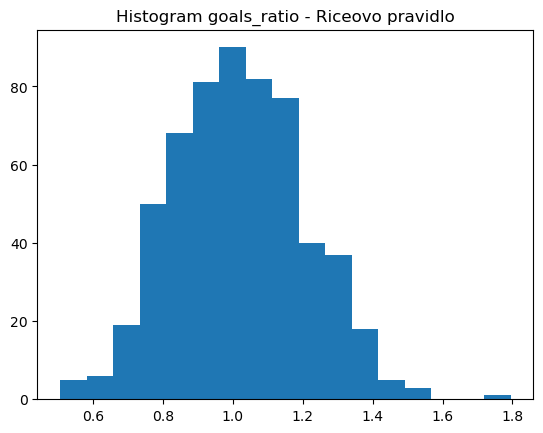

In [99]:
n = len(df["goals_ratio"])
bins_rice = int(-(-2 * n**(1/3)//1))
plt.hist(df["goals_ratio"], bins=bins_rice)
plt.title("Histogram goals_ratio - Riceovo pravidlo")
plt.show()


### Histogram of the variable using the square root rule

Text(0.5, 1.0, 'Histogram goals_ratio - Square Root Rule')

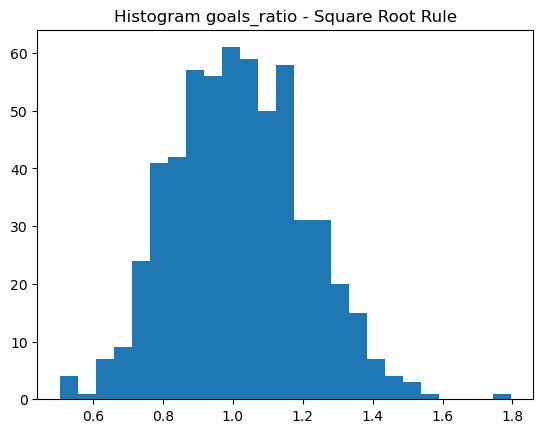

In [100]:
# Square Root Rule
bins_sqrt = int(-(-n**0.5//1))
plt.hist(df["goals_ratio"], bins=bins_sqrt)
plt.title("Histogram goals_ratio - Square Root Rule")

# `victory_percentage`

Similar to the analysis of the variable `goals_ratio`, we will conduct an exploratory analysis of `victory_percentage` by following these steps:  
- Determine the basic descriptive statistics, such as the mean, median, standard deviation, minimum, and maximum.  
- Examine the distribution of the variable by using a histogram to better understand its characteristics.  
- Check if there are any obvious subgroups of teams within the variable under analysis that could be identified based on specific criteria, such as the range of the variable's values.

### Descriptive Statistics

Průměr: 0.4585189003436426
Medián: 0.463
Směrodatná odchylka: 0.10223670092318196
Minimum: 0.11900000000000001
Maximum: 0.756


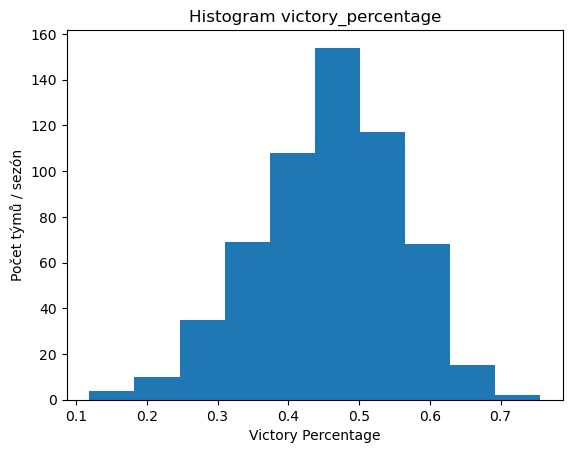

In [102]:
print("Průměr:", df["victory_percentage"].mean())
print("Medián:", df["victory_percentage"].median())
print("Směrodatná odchylka:", df["victory_percentage"].std())
print("Minimum:", df["victory_percentage"].min())
print("Maximum:", df["victory_percentage"].max())
plt.hist(df["victory_percentage"], bins=10)  # jednoduchých 10 sloupců
plt.title("Histogram victory_percentage")
plt.xlabel("Victory Percentage")
plt.ylabel("Počet týmů / sezón")
plt.show()

### Distribution

Here we will create the distribution of the variable, but we won't be doing it in two versions. Instead, we will choose a different, arbitrary number of intervals.

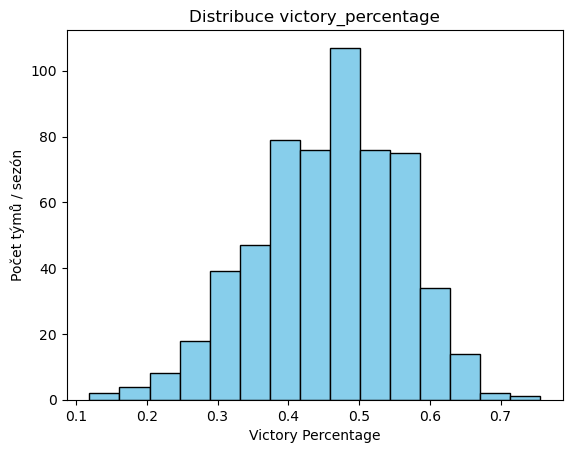

In [103]:
# Vytvoření histogramu s libovolným počtem intervalů, třeba 15
plt.hist(df["victory_percentage"], bins=15, color="skyblue", edgecolor="black")
plt.title("Distribuce victory_percentage")
plt.xlabel("Victory Percentage")
plt.ylabel("Počet týmů / sezón")
plt.show()

# `goals_ratio` vs `victory_percentage`

We have already analyzed `goals_ratio` and `victory_percentage` as two separate variables. Now, our task is to analyze them together to identify potential interdependencies between them.  
  
In this step, we will perform the following exercises:  
- Before starting the analysis, let’s consider whether these variables might be dependent or independent of each other. What kind of relationship can be expected based on their business descriptions?  
- We will create a scatterplot to visually represent the dependencies between these variables.  
- We will determine the relationship between the variables based on the scatterplot.  
- We will analyze the scatterplot to identify any outliers, paying special attention to their common distribution.

## Scatterplot of Variables

Now let's create a scatterplot for the two analyzed variables, `goals_ratio` and `victory_percentage`. After completing this step, let's answer the following questions:  
- What is the relationship between the variables `goals_ratio` and `victory_percentage`?  
- Can any outliers be identified in the plot? If so, what criteria were used to identify them?

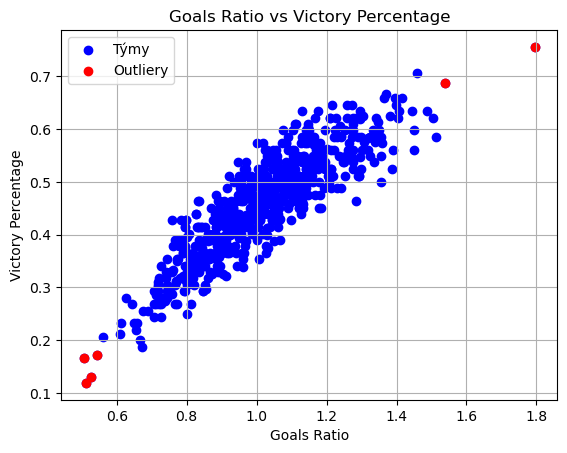

In [104]:
# Určíme základní statistiku
Q1_goals = df["goals_ratio"].quantile(0.25)
Q3_goals = df["goals_ratio"].quantile(0.75)
IQR_goals = Q3_goals - Q1_goals

Q1_vict = df["victory_percentage"].quantile(0.25)
Q3_vict = df["victory_percentage"].quantile(0.75)
IQR_vict = Q3_vict - Q1_vict

# Určíme outliery (mimo 1.5*IQR)
outliers = df[
    (df["goals_ratio"] < Q1_goals - 1.5*IQR_goals) |
    (df["goals_ratio"] > Q3_goals + 1.5*IQR_goals) |
    (df["victory_percentage"] < Q1_vict - 1.5*IQR_vict) |
    (df["victory_percentage"] > Q3_vict + 1.5*IQR_vict)
]

# Scatterplot
plt.scatter(df["goals_ratio"], df["victory_percentage"], color="blue", label="Týmy")
plt.scatter(outliers["goals_ratio"], outliers["victory_percentage"], color="red", label="Outliery")
plt.title("Goals Ratio vs Victory Percentage")
plt.xlabel("Goals Ratio")
plt.ylabel("Victory Percentage")
plt.legend()
plt.grid(True)
plt.show()

# Pokud body stoupají zleva doprava, existuje pozitivní vztah → lepší poměr gólů → vyšší procento výher.

# Pokud body nejsou nijak uspořádány, proměnné jsou pravděpodobně nezávislé


> space for chart analysis notes

If we have identified outlying observations at an earlier stage of analysis, let's now examine these specific cases. We will focus on outliers concerning the variables `goals_ratio` and `victory_percentage` to understand what features distinguish them.

The following steps should be taken for analysis:
1. Identify the specific outlying observations that were detected earlier.
2. Analyze the characteristics of these observations, paying attention to their values for the variables `goals_ratio` and `victory_percentage`.
3. Try to understand what might have caused their outlying nature. Are these instances of anomalies, or could they be the result of natural fluctuations in the data?

In [105]:
# Podíváme se na outliery detailně
print("Outliery podle goals_ratio a victory_percentage:")
print(outliers[["Team", "Season", "goals_ratio", "victory_percentage"]])

# Pro přehlednost můžeme seřadit podle goals_ratio
outliers_sorted = outliers.sort_values(by="goals_ratio", ascending=False)
print("\nSeřazeno podle goals_ratio:")
print(outliers_sorted[["Team", "Season", "goals_ratio", "victory_percentage"]])

Outliery podle goals_ratio a victory_percentage:
                  Team  Season  goals_ratio  victory_percentage
25   Atlanta Thrashers    1999     0.543131               0.171
413    Ottawa Senators    1992     0.511392               0.119
417    San Jose Sharks    1992     0.526570               0.131
439    Ottawa Senators    1993     0.506297               0.167
456  Detroit Red Wings    1994     1.538462               0.688
483  Detroit Red Wings    1995     1.795580               0.756

Seřazeno podle goals_ratio:
                  Team  Season  goals_ratio  victory_percentage
483  Detroit Red Wings    1995     1.795580               0.756
456  Detroit Red Wings    1994     1.538462               0.688
25   Atlanta Thrashers    1999     0.543131               0.171
417    San Jose Sharks    1992     0.526570               0.131
413    Ottawa Senators    1992     0.511392               0.119
439    Ottawa Senators    1993     0.506297               0.167


# Summary

In this notebook, we conducted a basic exploratory analysis of our dataset. The data was cleaned and then enriched with new variables, which we subjected to further analysis. The final step of this part is to save the processed data to a CSV file.  
  
**Let's save our data frame to the file:** `data/processed/hockey_teams.csv`, using a semicolon (`;`) as the column separator.

Next, in the following phase of our work, we will propose betting odds based on the analyzed historical data and discuss the results of this analysis.

### Writing the frame to the target location

- file name: `data/processed/hockey_teams.csv`,
- column separator: `;`,
- remember to disable index saving.

In [108]:
df.to_csv("../data/processed/hockey_teams.csv", sep=";",)
print("Soubor byl úspěšně uložen do data/processed/hockey_teams.csv")

Soubor byl úspěšně uložen do data/processed/hockey_teams.csv
